本 notebook 是 [M04.5 无监督学习](../notes/05-unsupervised-learning.qmd) 的实例讲解。

1. 1. 从零 Lloyd K-means 与框架对齐
2. 2. 一维 GMM 的 EM 与对数稳定性
3. 3. 聚类几何与超参数敏感性
4. 4. PCA 与 t-SNE 的不同目标

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.special import logsumexp
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.datasets import make_blobs, make_moons, make_swiss_roll
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

from semiai.plotting import BLUE, GRAY, ORANGE, PURPLE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 从零 Lloyd K-means 与框架对齐

固定初始化，在明显分离的三个合成团簇上重复分配与均值更新；检查目标单调下降并比较同一起点的框架结果。

In [2]:
X, _ = make_blobs(
    n_samples=300, centers=[[-3, -2], [0, 3], [3, -1]], cluster_std=0.5, random_state=42
)
initial = np.array([[-2.0, -2.0], [0.0, 2.0], [2.0, 0.0]])
centers = initial.copy()
history = []
for _ in range(40):
    distance = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    labels = distance.argmin(axis=1)
    new = np.array([X[labels == k].mean(axis=0) for k in range(3)])
    history.append(np.sum((X - new[labels]) ** 2))
    if np.allclose(new, centers, atol=1e-12):
        centers = new
        break
    centers = new
reference = KMeans(n_clusters=3, init=initial, n_init=1, algorithm="lloyd", tol=1e-12).fit(X)
print("中心最大差:", np.max(np.abs(centers - reference.cluster_centers_)), "目标:", history)
assert np.all(np.diff(history) <= 1e-10)
assert np.allclose(centers, reference.cluster_centers_, atol=1e-10)

中心最大差: 1.7763568394002505e-15 目标: [np.float64(140.29394996810964), np.float64(140.29394996810964)]


读法：交替更新到局部稳定点不等于全局最优；这里保证各簇非空，实际实现要规定空簇重置策略，并使用多次初始化。

## 2. 一维 GMM 的 EM 与对数稳定性

以 log-sum-exp 计算责任度，再更新权重、均值和方差，和相同初始化的 GaussianMixture 对照。

In [3]:
x = np.r_[rng.normal(-2, 0.5, 250), rng.normal(2, 0.8, 350)]
means = np.array([-1.5, 1.5])
variance = np.ones(2)
weight = np.ones(2) / 2
history = []
for _ in range(150):
    log_joint = (
        np.log(weight)
        - 0.5 * np.log(2 * np.pi * variance)
        - 0.5 * (x[:, None] - means) ** 2 / variance
    )
    normalizer = logsumexp(log_joint, axis=1)
    history.append(normalizer.sum())
    responsibility = np.exp(log_joint - normalizer[:, None])
    count = responsibility.sum(axis=0)
    weight = count / len(x)
    means = (responsibility * x[:, None]).sum(axis=0) / count
    variance = (responsibility * (x[:, None] - means) ** 2).sum(axis=0) / count + 1e-6
reference = GaussianMixture(
    2,
    means_init=np.array([[-1.5], [1.5]]),
    weights_init=[0.5, 0.5],
    precisions_init=np.ones((2, 1, 1)),
    tol=1e-10,
    max_iter=200,
    reg_covar=1e-6,
    random_state=42,
).fit(x[:, None])
print("EM means:", means, "library:", reference.means_.ravel(), "weights:", weight)
print("最小相邻似然变化:", np.min(np.diff(history)))
assert np.allclose(means, reference.means_.ravel(), atol=1e-5)
assert np.min(np.diff(history)) > -1e-7

EM means: [-2.03085188  1.98321139] library: [-2.03085164  1.9832117 ] weights: [0.41472417 0.58527583]
最小相邻似然变化: -2.2737367544323206e-13


读法：GMM 给出软分配但仍依赖分量形状与数目；对角小正则防止协方差坍缩，混合标签本身可以交换。

## 3. 聚类几何与超参数敏感性

在弯曲双月数据上比较 Ward 与 DBSCAN；借已知合成标签计算 ARI，现实无标签时不能凭此选择。

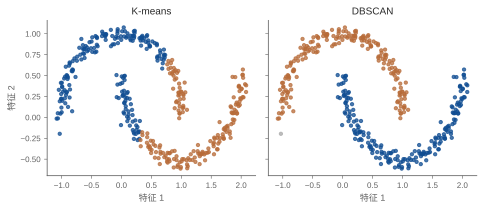

Ward ARI: 0.48184717629755003
eps 0.09 簇数 13 噪声比例 0.0425 ARI 0.17343071978609223 silhouette 0.4568260739470038
eps 0.18 簇数 2 噪声比例 0.0025 ARI 0.9950124376554706 silhouette 0.32710651085937476
eps 0.35 簇数 2 噪声比例 0.0 ARI 1.0 silhouette 0.32656436921712884


In [4]:
X, truth = make_moons(n_samples=400, noise=0.055, random_state=42)
labels = [
    KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X),
    DBSCAN(eps=0.18, min_samples=6).fit_predict(X),
]
fig, axes = plt.subplots(1, 2, figsize=(6.8, 3), sharex=True, sharey=True)
for ax, label, title in zip(axes, labels, ["K-means", "DBSCAN"], strict=True):
    for k in np.unique(label):
        mask = label == k
        color = GRAY if k == -1 else [BLUE, ORANGE, PURPLE][k % 3]
        ax.scatter(X[mask, 0], X[mask, 1], s=11, color=color, alpha=0.75)
    ax.set(title=title, xlabel="特征 1")
axes[0].set_ylabel("特征 2")
fig.tight_layout()
plt.show()

ward = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X)
print("Ward ARI:", adjusted_rand_score(truth, ward))
for eps in [0.09, 0.18, 0.35]:
    label = DBSCAN(eps=eps, min_samples=6).fit_predict(X)
    valid = label >= 0
    k = len(np.unique(label[valid]))
    silhouette = silhouette_score(X[valid], label[valid]) if k > 1 else np.nan
    print(
        "eps",
        eps,
        "簇数",
        k,
        "噪声比例",
        np.mean(~valid),
        "ARI",
        adjusted_rand_score(truth, label),
        "silhouette",
        silhouette,
    )

读法：Ward 偏好减小欧氏簇内平方差，DBSCAN 追踪密度连通；轮廓系数也有几何偏好，不能仅用最大轮廓分数判定科学上正确的簇。

## 4. PCA 与 t-SNE 的不同目标

在三维合成流形上计算 PCA 重构误差与 t-SNE 邻域保真；同时查看 t-SNE 的 KL 只对应其自身目标。

PCA 保留方差: 0.7183296029540809 重构 MSE: 0.2816703970459191


perplexity 8 KL 0.42194122076034546 trustworthiness 0.9959427828348505


perplexity 40 KL 0.48418471217155457 trustworthiness 0.9965019505851755


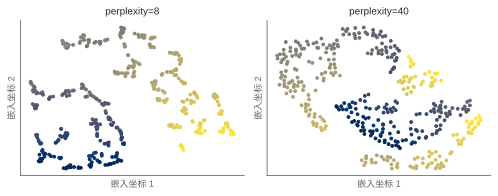

In [5]:
X, position = make_swiss_roll(n_samples=400, noise=0.1, random_state=42)
X = StandardScaler().fit_transform(X)
pca = PCA(2).fit(X)
z = pca.transform(X)
print(
    "PCA 保留方差:",
    pca.explained_variance_ratio_.sum(),
    "重构 MSE:",
    np.mean((X - pca.inverse_transform(z)) ** 2),
)
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8))
for ax, p in zip(axes, [8, 40], strict=True):
    model = TSNE(perplexity=p, init="pca", max_iter=600, learning_rate="auto", random_state=42)
    embedding = model.fit_transform(X)
    print(
        "perplexity",
        p,
        "KL",
        model.kl_divergence_,
        "trustworthiness",
        trustworthiness(X, embedding, n_neighbors=10),
    )
    ax.scatter(embedding[:, 0], embedding[:, 1], c=position, cmap="cividis", s=8)
    ax.set(title=f"perplexity={p}", xlabel="嵌入坐标 1", ylabel="嵌入坐标 2", xticks=[], yticks=[])
fig.tight_layout()
plt.show()

读法：不同 perplexity 定义不同高维邻域分布，不能仅以跨设置 KL 大小排最佳图；颜色只标记已知流形位置，坐标轴不具有物理单位。

## 小结

无监督算法的输出应与其目标共同解释。K-means 强调中心平方距离，GMM 强调混合密度，层次法强调合并规则，DBSCAN 强调密度连通；PCA 与流形嵌入保留不同关系。稳定性、原空间核验和领域证据决定这些输出能够支持什么结论。